# Scale-aware segmentation

Sea ice floes span length scales from meters to 10s of kilometers. As such, segmentation methods adapted for the problem of sea ice floe identification require different approaches than typical segmentation analysis. Using pairs of clear-sky images, we can estimate motion vector fields and identify discontinuities. 

In [1]:
using Pkg
Pkg.activate("../scripts/calval/")
using IceFloeTracker
using Images
using DataFrames

begin
    case_number = "001-" # Note: Hyphen prevents this from matching years, e.g. 201001    
    dataloc = "/Users/dmw/Documents/research/ift_fram_strait_test_cases/data/modis/"
    falsecolor_files = filter(f -> f != ".DS_Store", readdir(joinpath(dataloc, "falsecolor")))
    falsecolor_files = filter(f -> occursin(case_number, f), falsecolor_files)
    sort!(falsecolor_files)
    truecolor_files = replace.(falsecolor_files, ("falsecolor" => "truecolor"))
    landmask_file = joinpath(dataloc, "landmask.tiff")
    landmask_img = Gray.(load(landmask_file)) .> 0;
    tile_settings = (; rblocks=4, cblocks=2)
    clip=2
end

  Activating project at `~/Documents/research/calval_tgrs/scripts/calval`


2

In [2]:
truecolor_files

10-element Vector{String}:
 "001-fram_strait-20120412.aqua.truecolor.250m.png"
 "001-fram_strait-20120412.terra.truecolor.250m.png"
 "001-fram_strait-20120413.aqua.truecolor.250m.png"
 "001-fram_strait-20120413.terra.truecolor.250m.png"
 "001-fram_strait-20120414.aqua.truecolor.250m.png"
 "001-fram_strait-20120414.terra.truecolor.250m.png"
 "001-fram_strait-20120415.aqua.truecolor.250m.png"
 "001-fram_strait-20120415.terra.truecolor.250m.png"
 "001-fram_strait-20120416.aqua.truecolor.250m.png"
 "001-fram_strait-20120416.terra.truecolor.250m.png"

In [3]:
idx = 1
tc_imgs = load.(joinpath.([dataloc], ["truecolor"], truecolor_files[idx:idx+1])) .|> r -> RGB.(r)
fc_imgs = load.(joinpath.([dataloc], ["falsecolor"], falsecolor_files[idx:idx+1])).|> r -> RGB.(r);


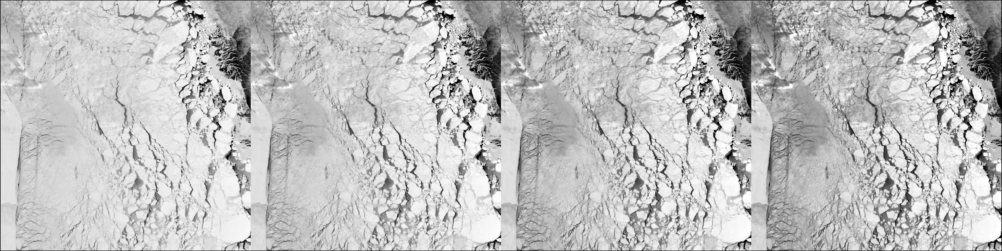

In [6]:
include("../scripts/dev/segmentation.jl")

gray_imgs =
[Preprocess(
    adapthisteq_algorithm = ContrastLimitedAdaptiveHistogramEqualization(
            nbins=256, rblocks=4, cblocks=4, clip=i
        )
    )(tc_imgs[1], landmask_img) for i in 1:4]
tile = (1000:2000, 1500:2500)
mosaicview([img[tile...] for img in gray_imgs]..., nrow=1)

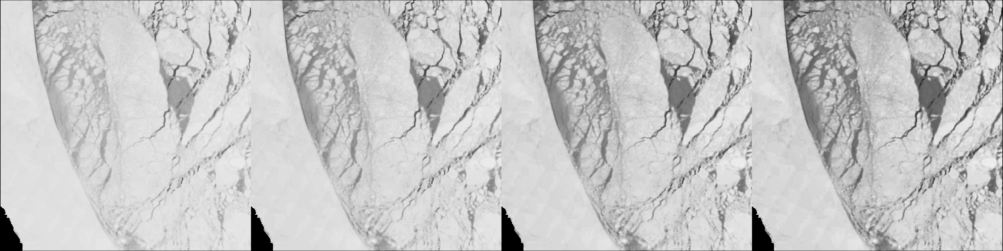

In [7]:
tile = (2000:2500, 1500:2000)
mosaicview([img[tile...] for img in gray_imgs]..., nrow=1)

In [8]:
preproc_gray = Preprocess(
    adapthisteq_algorithm = ContrastLimitedAdaptiveHistogramEqualization(
            nbins=256, rblocks=4, cblocks=4, clip=3
        )
    ).(tc_imgs, [landmask_img]);

The distinction between ice floes is ambiguous without motion information. In this image, we can see the initial formation of leads, and we can see that one of the larger floes contains numerous fused smaller floes. In this case, the large object near the image center is a large, fused region of pack ice in the process of breaking off and drifting. One interesting question for fracture is whether we can demonstrate that objects such as this fracture through the existing heterogeneities or if the fracture is independent of the structure.

With near-in-time images, we can produce detailed maps of vectors to identify which areas of ice are moving together.

In [28]:
?ORB

search: ORB ARGB XRGB



```julia
orb_params = ORB([num_keypoints = 500], [n_fast = 12], [threshold = 0.25], [harris_factor = 0.04], [downsample = 1.3], [levels = 8], [sigma = 1.2])
```

| Argument          | Type    | Description                                                                                               |
|:----------------- |:------- |:--------------------------------------------------------------------------------------------------------- |
| **num_keypoints** | Int     | Number of keypoints to extract and size of the descriptor calculated                                      |
| **n_fast**        | Int     | Number of consecutive pixels used for finding corners with FAST. See [`fastcorners`]                      |
| **threshold**     | Float64 | Threshold used to find corners in FAST. See [`fastcorners`]                                               |
| **harris_factor** | Float64 | Harris factor `k` used to rank keypoints by harris responses and extract the best ones                    |
| **downsample**    | Float64 | Downsampling parameter used while building the gaussian pyramid. See [`gaussian_pyramid`] in Images.jl    |
| **levels**        | Int     | Number of levels in the gaussian pyramid.  See [`gaussian_pyramid`] in Images.jl                          |
| **sigma**         | Float64 | Used for gaussian smoothing in each level of the gaussian pyramid.  See [`gaussian_pyramid`] in Images.jl |


Notes on using ORB feature tracking
* It works best if the edges are distinct
* When the landmask is present it tends to find corners there
* I haven't done anything to tune the choice of keypoints at all
* For tiles of approx 1000 pixels, getting keypoints and matches takes less than 20 seconds
* We could use segmentation to identify reasonable points for feature tracking

In [43]:
using ImageFeatures

tile = (1000:2000, 1500:2500)

orb_params = ORB(num_keypoints = 20000, threshold=0.05)
img1 = apply_landmask(complement.(preproc_gray[1][tile...]), landmask_img[tile...])
img2 = apply_landmask(complement.(preproc_gray[2][tile...]), landmask_img[tile...])

@time begin
    desc_1, ret_keypoints_1 = create_descriptor(img1, orb_params)
    desc_2, ret_keypoints_2 = create_descriptor(img2, orb_params)
end
nothing

  0.335486 seconds (530.24 k allocations: 219.917 MiB, 6.11% gc time, 19.16% compilation time)


In [44]:
@time begin
matches = match_keypoints(ret_keypoints_1, ret_keypoints_2, desc_1, desc_2, 0.2);
end

 13.935718 seconds (1.20 G allocations: 55.090 GiB, 19.33% gc time)


8663-element Vector{Vector{CartesianIndex{2}}}:
 [CartesianIndex(21, 478), CartesianIndex(30, 480)]
 [CartesianIndex(17, 478), CartesianIndex(29, 481)]
 [CartesianIndex(39, 307), CartesianIndex(49, 309)]
 [CartesianIndex(19, 478), CartesianIndex(24, 481)]
 [CartesianIndex(44, 470), CartesianIndex(54, 472)]
 [CartesianIndex(367, 362), CartesianIndex(371, 365)]
 [CartesianIndex(120, 418), CartesianIndex(128, 420)]
 [CartesianIndex(19, 477), CartesianIndex(27, 479)]
 [CartesianIndex(37, 447), CartesianIndex(47, 448)]
 [CartesianIndex(36, 447), CartesianIndex(46, 448)]
 [CartesianIndex(20, 477), CartesianIndex(28, 479)]
 [CartesianIndex(20, 478), CartesianIndex(29, 480)]
 [CartesianIndex(120, 419), CartesianIndex(128, 421)]
 ⋮
 [CartesianIndex(149, 424), CartesianIndex(154, 429)]
 [CartesianIndex(213, 162), CartesianIndex(221, 166)]
 [CartesianIndex(162, 110), CartesianIndex(171, 115)]
 [CartesianIndex(127, 380), CartesianIndex(137, 382)]
 [CartesianIndex(116, 178), CartesianIndex(126, 179

In [45]:
img1_matched_points = first.(matches)
img2_matched_points = last.(matches);

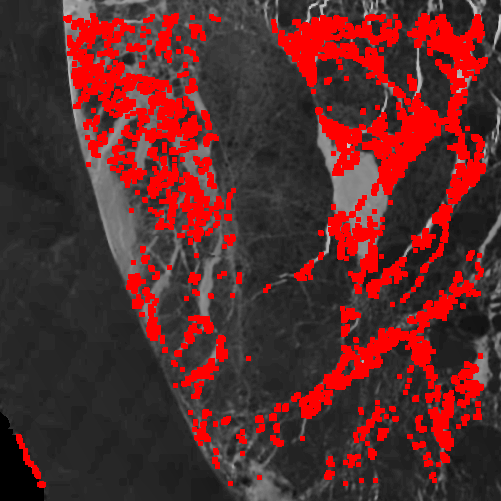

In [46]:
# check methods for coloring in points
test_keypoints = zeros(size(img1))
test_keypoints[img1_matched_points] .= 1
test_keypoints .= dilate(copy(test_keypoints), strel_box((5,5)))
cview = RGB.(img1)
cview[test_keypoints .> 0] .= RGB(1,0,0)
save("../figures/test_keypoints5.png", cview)
cview

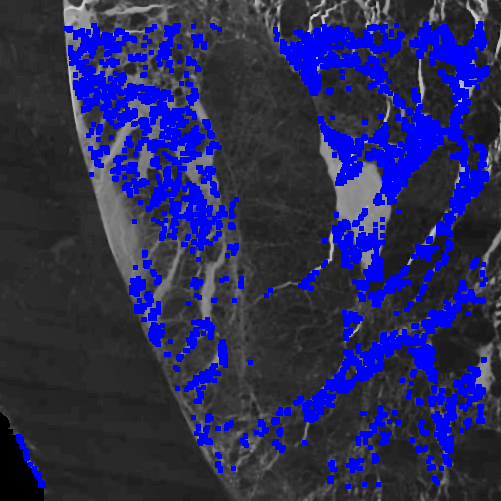

In [47]:

test_keypoints = zeros(size(img1))
test_keypoints[img2_matched_points] .= 1
test_keypoints .= dilate(copy(test_keypoints), strel_box((5,5)))
cview = RGB.(img2)
cview[test_keypoints .> 0] .= RGB(0,0,1)
save("../figures/test_keypoints6.png", cview)
cview

The keypoint matches work well, but obviously we can do better -- there are lots of potential features to match here.

In [ ]:
using CairoMakie

[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0](cache misses: wrong dep version loaded (5), incompatible header (4))
[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0] (cache misses: wrong dep version loaded (10), incompatible header (8))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling IntervalArithmeticRecipesBaseExt [e3b91bd4-2888-5303-85ed-4cf5ebb38ff1](cache misses: wrong dep version loaded (4), incompatible header (4))
[ Info: Precompiling IntervalArithmeticRecipesBaseE